# Analyse Exploratoire des Données - ClinTox

Ce notebook explore le dataset **ClinTox**, qui regroupe des molécules approuvées par la FDA et des molécules ayant échoué aux essais cliniques pour cause de toxicité.

**Objectif :** comprendre la distribution des classes, les propriétés physico-chimiques, et la structure des molécules avant toute modélisation.

| Colonne | Description |
|---------|-------------|
| Smiles | Représentation textuelle de la molécule |
| FDA_Approved | 1 = approuvée par la FDA |
| CT_Tox | 1 = toxique en essais cliniques |

## 1. Chargement des données

In [46]:
import pandas as pd

df = pd.read_csv("../data/raw/clintox.csv")

### Aperçu des premières lignes

In [47]:
df.head(5)

,smiles,FDA_APPROVED,CT_TOX
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1,0
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1,0
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1,0
3,[H]/[NH+]=C(/C1=CC(=O)/C(=C\C=c2ccc(=C([NH3+])...,1,0
4,[H]/[NH+]=C(\N)/c1ccc(cc1)OCCCCCOc2ccc(cc2)/C(...,1,0


### Dimensions du dataset

In [48]:
df.shape

(1484, 3)

### Types des colonnes

In [49]:
df.dtypes

smiles          object
FDA_APPROVED     int64
CT_TOX           int64
dtype: object

### Valeurs manquantes

In [50]:
df.isnull().sum()

smiles          0
FDA_APPROVED    0
CT_TOX          0
dtype: int64

## 2. Distribution des classes

On vérifie le déséquilibre entre molécules toxiques () et non-toxiques ().  
Un fort déséquilibre nécessitera un rééchantillonnage ou une pondération lors de l'entraînement.

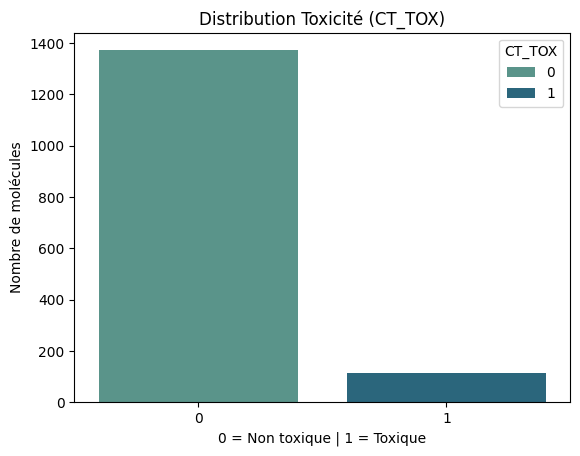

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_palette("pastel")

# Distribution CT_TOX
sns.barplot(x=df['CT_TOX'].value_counts().index, y=df['CT_TOX'].value_counts().values, hue=df['CT_TOX'].value_counts().index, palette="crest")
plt.title("Distribution Toxicité (CT_TOX)")
plt.xlabel("0 = Non toxique | 1 = Toxique")
plt.ylabel("Nombre de molécules")
plt.savefig("../reports/figures/class_distribution.png")

### Visualisation 2D des molécules

Rendu structural de 3 molécules non-toxiques et 3 toxiques pour une inspection visuelle rapide.

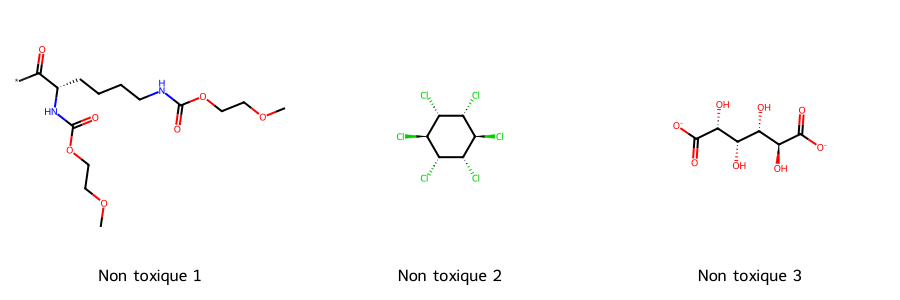

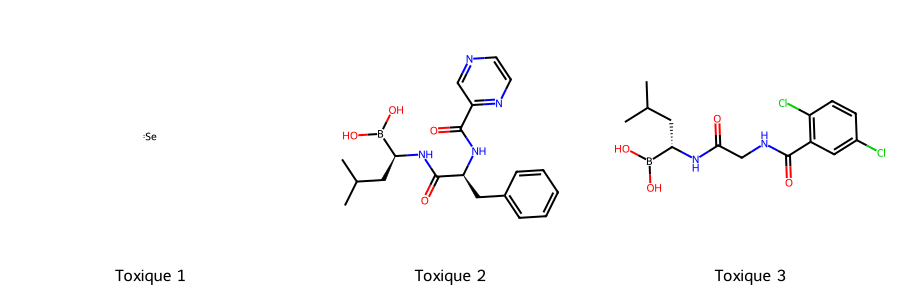

In [52]:
from rdkit.Chem import Draw
from rdkit import Chem
from rdkit.Chem import Descriptors


# Selectionner 3 molecules non-toxiques et 3 toxiques
mols_non_toxic = [Chem.MolFromSmiles(s) for s in df[df['CT_TOX'] == 0]['smiles'].head(3)]
mols_toxic     = [Chem.MolFromSmiles(s) for s in df[df['CT_TOX'] == 1]['smiles'].head(3)]

img_non_toxic = Draw.MolsToGridImage(
    mols_non_toxic,
    molsPerRow=3,
    subImgSize=(300, 300),
    legends=[f"Non toxique {i+1}" for i in range(3)],
    returnPNG=False
)

img_toxique = Draw.MolsToGridImage(
    mols_toxic,
    molsPerRow=3,
    subImgSize=(300, 300),
    legends=[f"Toxique {i+1}" for i in range(3)],
    returnPNG=False
)

img_non_toxic.save("../reports/figures/non_toxic_molecules.png")
img_toxique.save("../reports/figures/toxic_molecules.png")
display(img_non_toxic)
display(img_toxique)

## 3. Propriétés physico-chimiques

On calcule six descripteurs moléculaires classiques issus de la **règle de Lipinski** :

| Descripteur | Signification | Seuil drug-like |
|-------------|---------------|-----------------|
|  | Poids moléculaire | ≤ 500 Da |
|  | Lipophilicité | ≤ 5 |
|  | Surface polaire topologique | — |
|  | Donneurs de liaisons H | ≤ 5 |
|  | Accepteurs de liaisons H | ≤ 10 |
|  | Liaisons rotatables (flexibilité) | — |

### Validation des SMILES

On filtre les SMILES invalides avant tout calcul de descripteurs.

In [53]:
# Vérifier que tous les SMILES sont valides
def is_valid(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return mol is not None

df['valid_smiles'] = df['smiles'].apply(is_valid)

print(f"SMILES valides   : {df['valid_smiles'].sum()}")
print(f"SMILES invalides : {(~df['valid_smiles']).sum()}")

# Supprimer les invalides
df = df[df['valid_smiles']].drop('valid_smiles', axis=1)

[17:28:05] Explicit valence for atom # 0 N, 4, is greater than permitted
[17:28:05] Can't kekulize mol.  Unkekulized atoms: 9


SMILES valides   : 1480
SMILES invalides : 4


[17:28:06] Can't kekulize mol.  Unkekulized atoms: 4
[17:28:06] Can't kekulize mol.  Unkekulized atoms: 4


### Calcul des descripteurs

In [54]:
def compute_properties(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return {
        'MW'       : Descriptors.MolWt(mol),          # Poids moléculaire
        'LogP'     : Descriptors.MolLogP(mol),         # Solubilité
        'TPSA'     : Descriptors.TPSA(mol),            # Surface polaire
        'HBD'      : Descriptors.NumHDonors(mol),      # Donneurs H
        'HBA'      : Descriptors.NumHAcceptors(mol),   # Accepteurs H
        'RotBonds' : Descriptors.NumRotatableBonds(mol) # Flexibilité
    }

props = df['smiles'].apply(compute_properties)
props_df = pd.DataFrame(props.tolist())
df = pd.concat([df, props_df], axis=1)

### Comparaison des descripteurs par classe

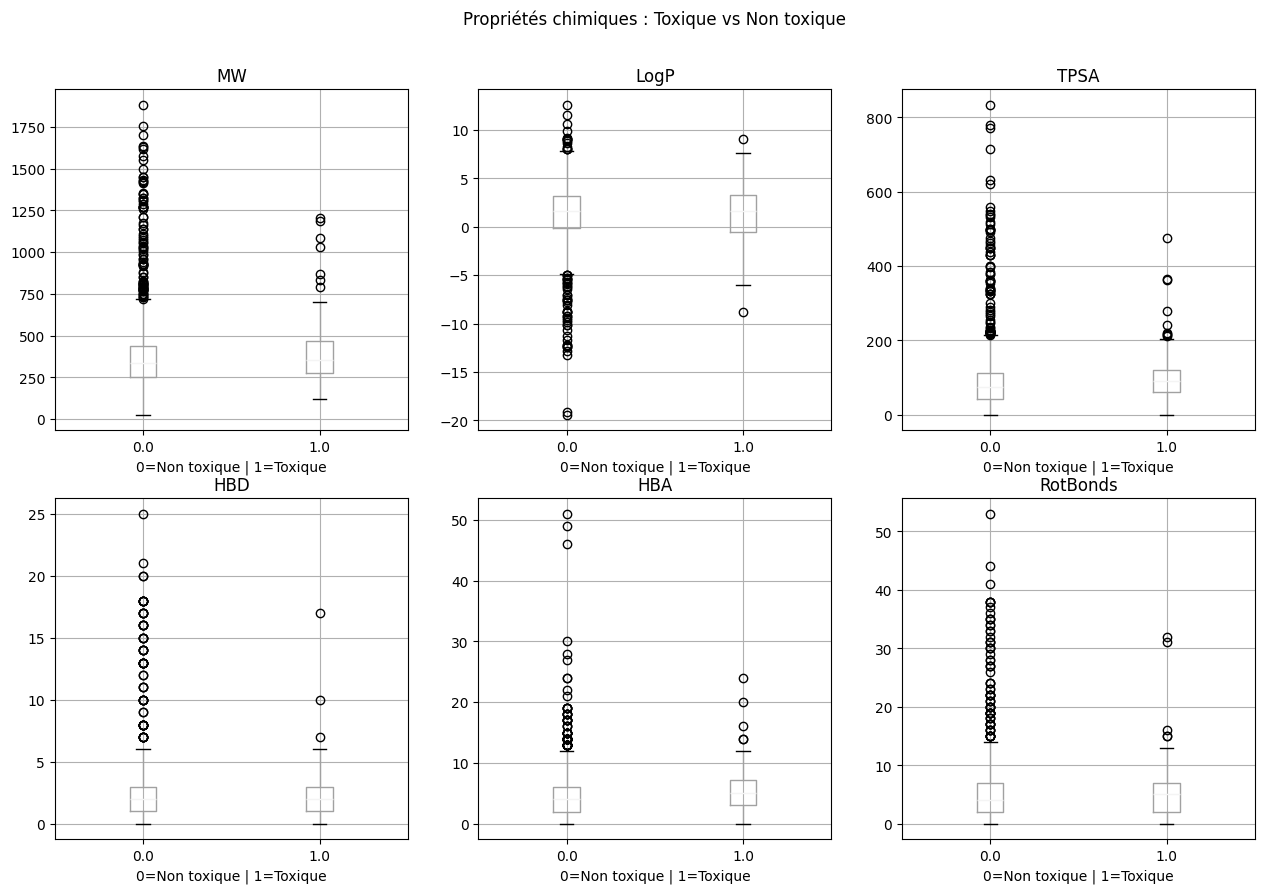

In [55]:
# Boxplots pour chaque propriété
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

properties = ['MW', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotBonds']

for ax, prop in zip(axes.flatten(), properties):
    df.boxplot(column=prop, by='CT_TOX', ax=ax)
    ax.set_title(prop)
    ax.set_xlabel("0=Non toxique | 1=Toxique")

plt.suptitle("Propriétés chimiques : Toxique vs Non toxique")
plt.savefig("../reports/figures/properties_comparison.png")

### Vérification du DataFrame après ajout des descripteurs

In [56]:
df.head()

,smiles,FDA_APPROVED,CT_TOX,MW,LogP,TPSA,HBD,HBA,RotBonds
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1.0,0.0,333.361,0.3464,112.19,2.0,7.0,13.0
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1.0,0.0,290.832,3.6444,0.00,0.0,0.0,0.0
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1.0,0.0,208.122,-6.0702,161.18,4.0,8.0,5.0
3,[H]/[NH+]=C(/C1=CC(=O)/C(=C\C=c2ccc(=C([NH3+])...,1.0,0.0,282.347,-3.1586,122.34,4.0,2.0,2.0
4,[H]/[NH+]=C(\N)/c1ccc(cc1)OCCCCCOc2ccc(cc2)/C(...,1.0,0.0,342.443,-0.7565,121.68,4.0,2.0,10.0


### Règle de Lipinski

Une molécule est **drug-like** si elle respecte simultanément : MW ≤ 500, LogP ≤ 5, HBD ≤ 5, HBA ≤ 10.  
On vérifie si la conformité à cette règle est corrélée à la toxicité.

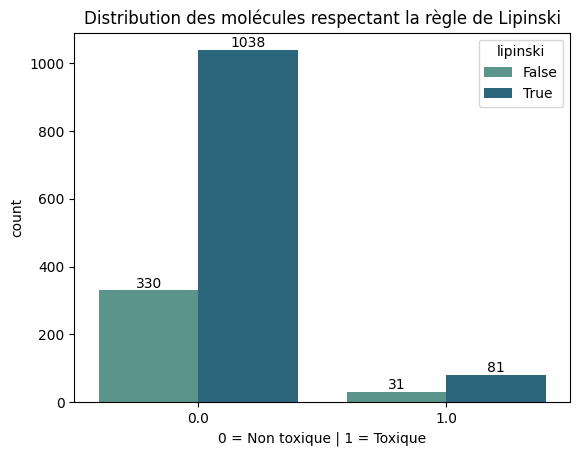

In [57]:
# Une molécule est "drug-like" si :
# MW <= 500, LogP <= 5, HBD <= 5, HBA <= 10

def lipinski(row):
    return (
        row['MW']  <= 500 and
        row['LogP'] <= 5   and
        row['HBD']  <= 5   and
        row['HBA']  <= 10
    )

df['lipinski'] = df.apply(lipinski, axis=1)

ax = sns.countplot(data=df, x='CT_TOX', hue='lipinski', palette="crest")

ax.bar_label(ax.containers[0], label_type='edge', fmt='%d')
ax.bar_label(ax.containers[1], label_type='edge', fmt='%d')
ax.set_title("Distribution des molécules respectant la règle de Lipinski")
ax.set_xlabel("0 = Non toxique | 1 = Toxique")
plt.savefig("../reports/figures/lipinski_distribution.png")

### Matrice de corrélation des descripteurs

On identifie les paires de descripteurs redondantes, ce qui guidera la sélection de features pour le modèle.

<Axes: >

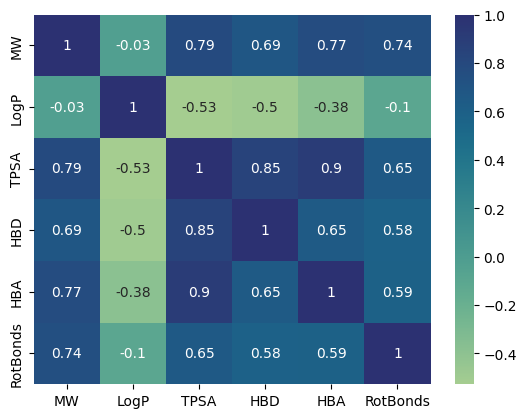

In [58]:
sns.heatmap(df[['MW','LogP','TPSA','HBD','HBA','RotBonds']].corr(), annot=True, cmap='crest')


### DataFrame final

In [59]:
df.head()

,smiles,FDA_APPROVED,CT_TOX,MW,LogP,TPSA,HBD,HBA,RotBonds,lipinski
0,*C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1.0,0.0,333.361,0.3464,112.19,2.0,7.0,13.0,True
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1.0,0.0,290.832,3.6444,0.00,0.0,0.0,0.0,True
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1.0,0.0,208.122,-6.0702,161.18,4.0,8.0,5.0,True
3,[H]/[NH+]=C(/C1=CC(=O)/C(=C\C=c2ccc(=C([NH3+])...,1.0,0.0,282.347,-3.1586,122.34,4.0,2.0,2.0,True
4,[H]/[NH+]=C(\N)/c1ccc(cc1)OCCCCCOc2ccc(cc2)/C(...,1.0,0.0,342.443,-0.7565,121.68,4.0,2.0,10.0,True


## Morgan Fingerprints

Les **Morgan Fingerprints** (ECFP4) encodent la structure locale de chaque atome jusqu'à un rayon de 2, sur 2048 bits.

In [60]:
import numpy as np
from rdkit.Chem import rdFingerprintGenerator

RADIUS = 2
N_BITS = 2048

_gen = rdFingerprintGenerator.GetMorganGenerator(radius=RADIUS, fpSize=N_BITS)

def morgan_fp(smiles):
    if not isinstance(smiles, str):
        return np.zeros(N_BITS, dtype=np.uint8)
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(N_BITS, dtype=np.uint8)
    fp = _gen.GetFingerprintAsNumPy(mol)
    return fp.astype(np.uint8)

fp_matrix = np.vstack(df['smiles'].apply(morgan_fp).values)
labels    = df['CT_TOX'].values.astype(int)

print(f"Matrice fingerprints : {fp_matrix.shape}")
print(f"Densite moyenne      : {fp_matrix.mean():.4f}")

Matrice fingerprints : (1484, 2048)
Densite moyenne      : 0.0213


C:\Users\hp\AppData\Local\Temp\ipykernel_13060\74768423.py:19: RuntimeWarning: invalid value encountered in cast
  labels    = df['CT_TOX'].values.astype(int)


### 1. Projection PCA

Projection 2D des fingerprints pour visualiser la séparation entre classes.

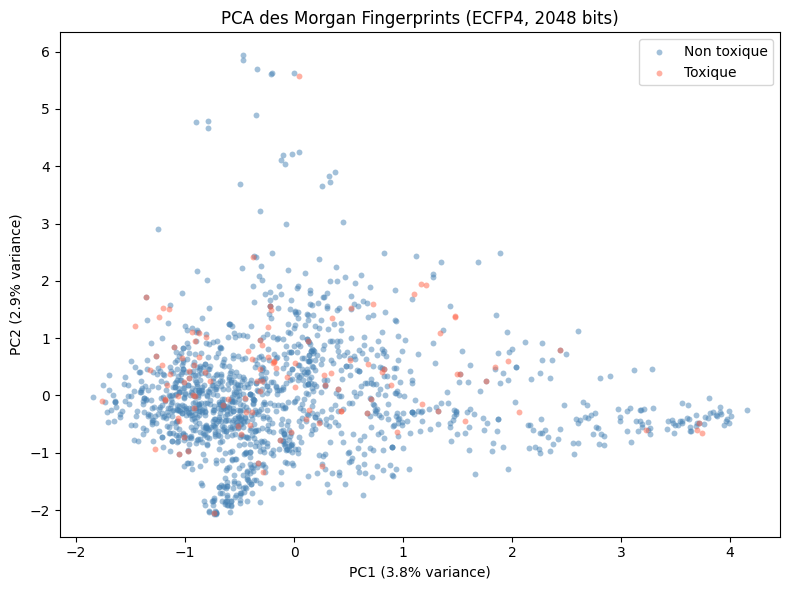

In [61]:
from sklearn.decomposition import PCA

pca    = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(fp_matrix)

fig, ax = plt.subplots(figsize=(8, 6))
for cls, color, label in [(0, "steelblue", "Non toxique"), (1, "tomato", "Toxique")]:
    mask = labels == cls
    ax.scatter(coords[mask, 0], coords[mask, 1], c=color, label=label, alpha=0.5, s=18, linewidths=0)

ax.set_title("PCA des Morgan Fingerprints (ECFP4, 2048 bits)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/morgan_pca.png", dpi=150)
plt.show()

### 2. Bits les plus discriminants

Différence de fréquence moyenne par bit entre molécules toxiques et non-toxiques.

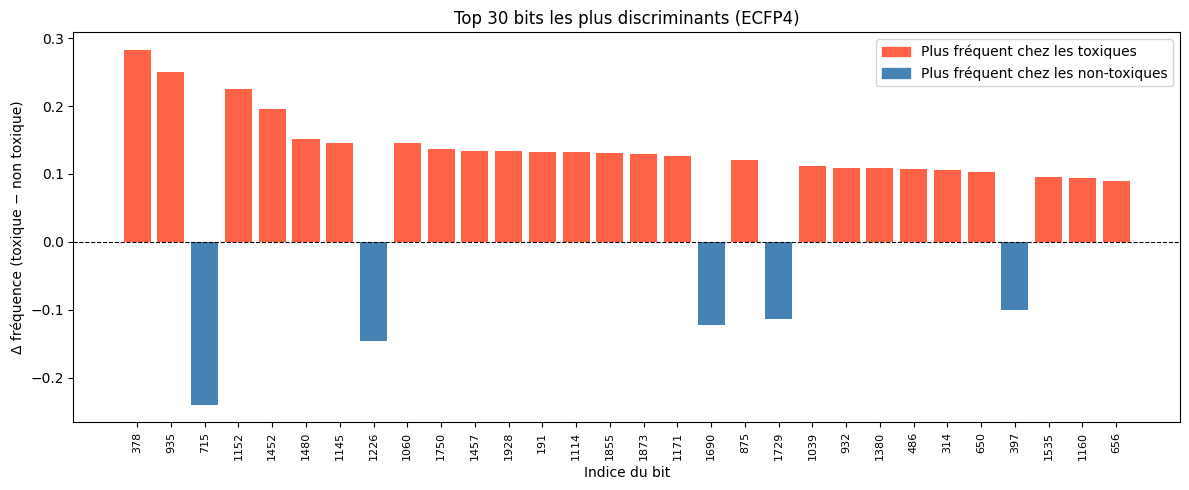

In [62]:
toxic_mask    = labels == 1
nontoxic_mask = labels == 0

freq_toxic    = fp_matrix[toxic_mask].mean(axis=0)
freq_nontoxic = fp_matrix[nontoxic_mask].mean(axis=0)
diff          = freq_toxic - freq_nontoxic

top_n   = 30
top_idx = np.argsort(np.abs(diff))[-top_n:][::-1]

fig, ax = plt.subplots(figsize=(12, 5))
bar_colors = ["tomato" if diff[i] > 0 else "steelblue" for i in top_idx]
ax.bar(range(top_n), diff[top_idx], color=bar_colors)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(range(top_n))
ax.set_xticklabels([str(i) for i in top_idx], rotation=90, fontsize=8)
ax.set_title(f"Top {top_n} bits les plus discriminants (ECFP4)")
ax.set_xlabel("Indice du bit")
ax.set_ylabel("Δ fréquence (toxique − non toxique)")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="tomato",    label="Plus fréquent chez les toxiques"),
    Patch(color="steelblue", label="Plus fréquent chez les non-toxiques"),
])
plt.tight_layout()
plt.savefig("../reports/figures/morgan_discriminant_bits.png", dpi=150)
plt.show()

### 3. Distribution de la similarité de Tanimoto

Comparaison intra-classe vs inter-classe sur un sous-échantillon.

[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerator
[17:28:11] DEPRECATION WARNING: please use MorganGenerat

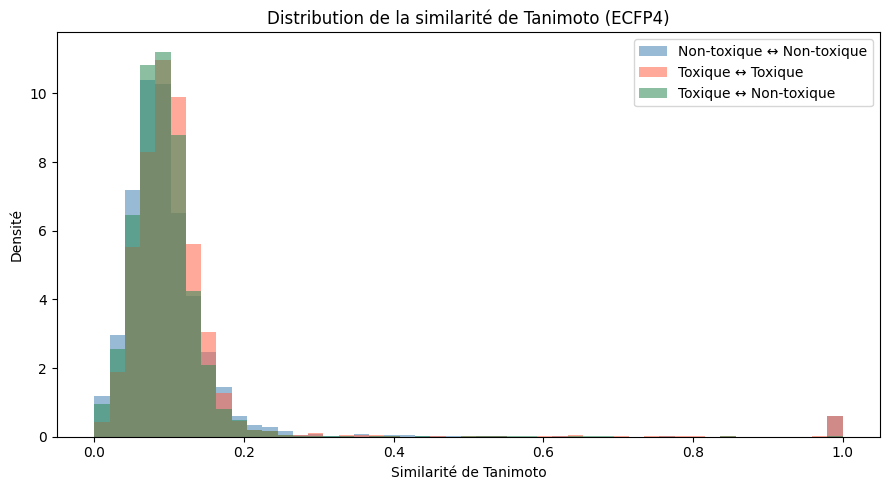

In [63]:
from rdkit import DataStructs

rng = np.random.default_rng(42)

def sample_mols(mask, n=80):
    idx = rng.choice(np.where(mask)[0], size=min(n, mask.sum()), replace=False)
    return [Chem.MolFromSmiles(df["smiles"].iloc[i]) for i in idx]

def tanimoto_pairs(mols_a, mols_b):
    fps_a = [AllChem.GetMorganFingerprintAsBitVect(m, radius=RADIUS, nBits=N_BITS) for m in mols_a]
    fps_b = [AllChem.GetMorganFingerprintAsBitVect(m, radius=RADIUS, nBits=N_BITS) for m in mols_b]
    return np.array([s for fa in fps_a for s in DataStructs.BulkTanimotoSimilarity(fa, fps_b)])

mols_tox    = sample_mols(toxic_mask)
mols_nontox = sample_mols(nontoxic_mask)

sim_tt = tanimoto_pairs(mols_tox,    mols_tox)
sim_nn = tanimoto_pairs(mols_nontox, mols_nontox)
sim_tn = tanimoto_pairs(mols_tox,    mols_nontox)

bins = np.linspace(0, 1, 50)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(sim_nn, bins=bins, alpha=0.55, color="steelblue", label="Non-toxique ↔ Non-toxique", density=True)
ax.hist(sim_tt, bins=bins, alpha=0.55, color="tomato",    label="Toxique ↔ Toxique",         density=True)
ax.hist(sim_tn, bins=bins, alpha=0.55, color="seagreen",  label="Toxique ↔ Non-toxique",     density=True)
ax.set_title("Distribution de la similarité de Tanimoto (ECFP4)")
ax.set_xlabel("Similarité de Tanimoto")
ax.set_ylabel("Densité")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/morgan_tanimoto.png", dpi=150)
plt.show()